# Project 1: Pattern Classification
**EQ2415 Machine learning for data science (HT 23)**

Perform all (or as many as you can) of the tasks in this project assignment. You are going to present your work to the teaching assistants (TA) and it pays off to have a clear, well structured and brief notebook. Include an algorithmic solution and/or numerical result and/or a graph illustrating your results. Your code should be functioning and easy to read. Also, wherever possible, include comments to your code to demonstrate your understanding and / or thought process. 

**Objective**
The goal of this project is to implement the inference methods introduced in previous tutorials, for pattern classification problems.

**Dataset**
We will use a standard image recognition dataset, the NIST dataset.
Today the dataset is widely used and can save some data preparation time by downloading it directly from the scikit-learn library. 

**Tasks**
The coding and discussion tasks are indicated through out the notebook. For answering questions in text, please use Markdown (a tutorial is available  [here](https://www.markdowntutorial.com/)). This is available by creating a cell and switching to Markdown mode (or equivalent keyboard shortcuts).

### On the use of generative AI

Please refrain from using code from ChatGPT or other sources such as GitHub Co-Pilot for coding assignments. The assignments are so that you can get experience with some implementation of machine learning algorithms in the first place. Since, the evaluation of the assignment will be based on a presentation, you are expected to **understand and explain** every aspect of your code and so copying doesn't help.

### Requirements

`numpy==1.23.2`

`scikit-learn==1.1.2`

`matplotlib==3.5.3`

`cvxopt==1.3.0`

`torch==1.10.1`

`torchvision==0.11.2`

In [1]:
from sklearn.datasets import load_digits, make_moons
import matplotlib.pyplot as plt
import numpy as np
import cvxopt
import sklearn.metrics as metrics
import sklearn.preprocessing as preprocessing

nist = load_digits()    # each image is 8x8 pixels, total of 1797 images

Let us start by visualising our dataset. This dataset contains images of handwritten 0-9 digits, and their corresponding class.

### Task
- Use the `plt.imshow` function to plot an example image from the dataset
- Print the class of the sample you display

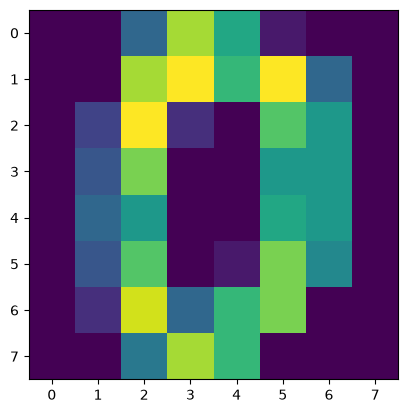

Class: 0


In [2]:
sample_idx = 0

plt.imshow(nist.images[sample_idx])     # I can also add (..., cmap="gray") for black/white picture
plt.show()

print("Class:", nist.target[sample_idx])    # vector of true labels, values from 0 to 9

## Part 1 - Linear models

Suppose that we can observe two variables: $\mathbf{x}\in\mathbb{R}^d$ and $\mathbf{y}\in\mathbb{R}^q$. 
Suppose also that these variables are related, and that we model this relation with a linear model parameterized with a matrix $A\in\mathbb{R}^{q\times d}$, i.e. such that \begin{equation}
    \mathbf{y}=A\mathbf{x}.
\end{equation}

In this part of the project, we will implement the MMSE solutions we derived for $A$ in tutorial 1.
Before that, we need to do some small transformations to our dataset input.

### Preparing the input data
You should have noted that the dataset consists in $N=1797$ images, represented as matrices of size $8 \times 8$. This is incompatible with our model which assumes that the data are vectors !

In the context of image recognition, $\mathbf{x}\in\mathbb{R}^d$ is the vectorized (i.e. the original matrix of size $8 \times 8$ is transformed into a vector of size $d=w\times h$) representation of an input image.

In [3]:
print("Input tensor shape:",nist.images.shape)

Input tensor shape: (1797, 8, 8)


### Task
- Transform the input tensor into a matrix $X$ of size $64 \times 1797$.

In [4]:
X = nist.images.reshape(1797, 64).T
print(X.shape)

(64, 1797)


### Preparing the target data

Here the target data is a sequence of $N$ digits, from $0$ to $9$.
For simplicity here, we will consider the default task of classifying each input image to it's corresponding 0-9 digit. This means that we need target vectors of dimension $q=10$.

In [5]:
print("Target shape:",nist.target.shape, "e.g.",nist.target[:11], "...")

Target shape: (1797,) e.g. [0 1 2 3 4 5 6 7 8 9 0] ...


The targets provided in the dataset are integer numbers (i.e. vectors of dimension $1$ !). We could consider a classification task with 1-dimension targets, however for classification tasks with $10$ classes, it is easier to encode the integer targets as 10-dimensional **one-hot vectors**.

A one-hot vector is a way to encode integer number as a vector. It is a vector where all the components have value $0$, except for one, corresponding to the encoded integer, with value $1$.
For instance, in our context with $10$ possible classes:
- integer $1$ will be represented as the 10-dimensional vector: $[0,1,0,0,0,0,0,0,0,0]^T$, 
- integer $9$ will be represented as the 10-dimensional vector: $[0,0,0,0,0,0,0,0,0,1]^T$, 

### Task
- Transform the target tensor into a matrix $Y$ of size $10 \times 1797$, containing the one-hot encoded vectors columnwise.

**Hint** The scikit-learn library contains tools to perform such transformations in module `sklearn.preprocessing`. You can also get it done using the `numpy` library only.

In [41]:
Y = np.eye(10)[nist.target].T       # .eye makes identity matrix 10x10, [nist.target] uses the labels as row indices
print(Y.shape)
# print(y[:, 0])
# print("first label: ", nist.target[0])

(10, 1797)


You should now have data represented as Question 2 in section 1.3 of tutorial 1.
This means that we are ready to implement the methods!

## Implementing the algorithms

In what follows, we suppose that we have $n=1797$ data points for $\mathbf{x}$ and $\mathbf{y}$, in the form of matrices $X\in\mathbb{R}^{d\times n}$ and $Y\in\mathbb{R}^{q\times n}$ respectively, with $q=10$ and $d=64$.

###  Regularized mean squared error solution

### Task
- Implement the method derived in question 3 of tutorial 1.
i.e. implement the method to calculate $A_n^\star$ which leads to the minimum mean squared error for the regularized linear model. **Hint** Use a regularization parameter $\lambda=1$ for debugging.

- Write a function to calculate the mean squared error.
- What is the mean squared error on the dataset for $\lambda=1$ ?

In [7]:
def get_mmse(X, Y, lam):
    # we get input dimenstion from X (X has shape (d, n) so d is the number of rows)
    I = np.eye(X.shape[0])  # identity matrix I

    if lam == 0:    # if lambda is 0 then XX.T may be singular 
        return Y @ X.T @ np.linalg.pinv(X @ X.T)
    else:
        return Y @ X.T @ np.linalg.inv(X @ X.T + lam * I)       # A* = Y X.T (X X.T + lambda I)^(-1)

def mse(Y, Yhat):
    sub = Y - Yhat      # compute the difference between true targets and predictions
    square = sub**2      # square every error value
    average = np.mean(square)     # Average over all entries

    return average      # return mean squared value

In [8]:
Astar = get_mmse(X, Y, 1)     # Compute the regularized linear model using lambda = 1.
# Use the learned model to predict outputs for all input images.
# Astar has shape (10, 64), X has shape (64, 1797),
# so Yhat has shape (10, 1797).
Yhat = Astar @ X

print(mse(Y,Yhat))
print(Yhat[:,0])    # prediction scores for the first image

0.031003030804744737
[ 0.7890884  -0.218721   -0.06162295  0.11173657  0.08963133 -0.03501363
 -0.04230774  0.01645999  0.09522369  0.15365058]


- 0.031003030804744737 means the predicted output vectors are, on average, close to the true one-hot label vectors


### Task
- What is the classification accuracy on the dataset for $\lambda=1$ ?

**Hint 1** To obtain an accuracy you should 
1. Transform the predictions you obtain with a softmax function (see below)
2. Classify each input vector by determining which row of the predicted vector has maximum value.

**Hint 2** The module `sklearn.metrics` contains a function to calculate the accuracy. You can also compute it using only `numpy`

In [9]:
def softmax(Y):
    """Matrix of size (q x n), with prediction vectors columnwise."""
    # Convert raw prediction scores into probability-like values.
    # Each column corresponds to one sample.
    # np.exp(Y) exponentiates all scores.
    # np.exp(Y).sum(0) sums each column, so each column is normalized.
    return np.exp(Y)/np.exp(Y).sum(0)

Yhat_softmax = softmax(Yhat)    # This makes each prediction vector sum to 1.
# For each sample/column, choose the row/class with the largest value.
# axis=0 means we take argmax down the rows, separately for each column.
predicted_labels = np.argmax(Yhat_softmax, axis=0)
true_labels = nist.target       # The true labels are the original digit labels from the dataset

accuracy = metrics.accuracy_score(true_labels, predicted_labels)

print(accuracy)

0.9471341124095715


- Our model correctly classifies about 94.7%

### Task
1. Plot the MSE against the regularization parameter $\lambda$. Vary $\lambda$ in an interval you find relevant.
2. What do you expect to see when the value of $\lambda$ becomes large ? Does this match with the observation you can make from your graph ?
3. Propose an explaination for what you see on the graph.
4. Repeat tasks 1-3 with the accuracy instead of the MSE (you can use the same interval for $\lambda$).

In [10]:
# code for the diff lambda values
lambda_values = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000]
mse_val = []
acc_val = []

for lam in lambda_values:
    Astar = get_mmse(X,Y,lam)   # Train the regularized linear model
    Yhat = Astar @ X    # Predict the output scores for all digit images

    mse_val.append(mse(Y, Yhat))

    Yhat_softmax = softmax(Yhat)
    predicted_labels = np.argmax(Yhat_softmax, axis=0)
    true_labels = nist.target

    acc_val.append(metrics.accuracy_score(true_labels, predicted_labels))


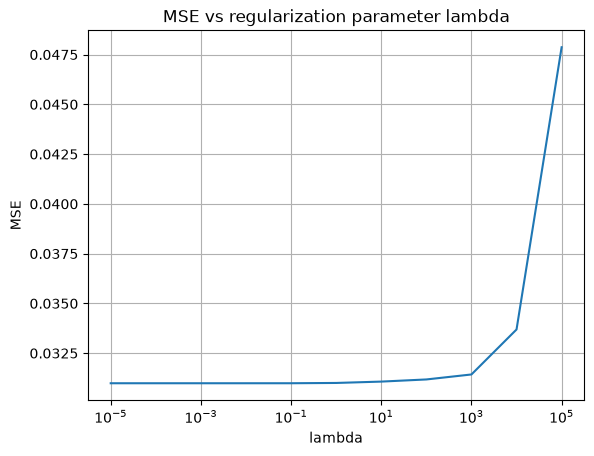

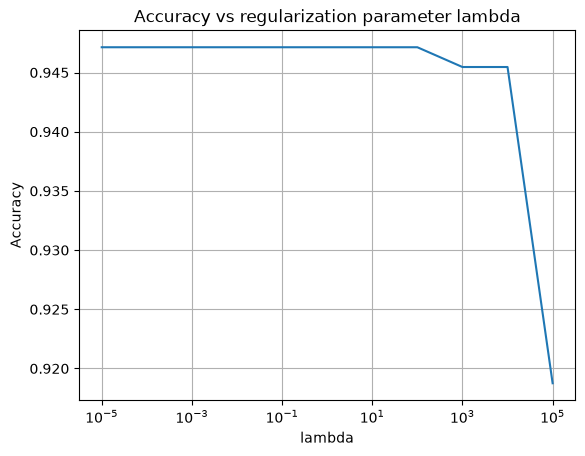

In [11]:
# plot MSE
plt.figure()
plt.plot(lambda_values, mse_val)
plt.xscale("log")
plt.xlabel("lambda")
plt.ylabel("MSE")
plt.title("MSE vs regularization parameter lambda")
plt.grid(True)
plt.show()

# plot accuracy
plt.figure()
plt.plot(lambda_values, acc_val)
plt.xscale("log")
plt.xlabel("lambda")
plt.ylabel("Accuracy")
plt.title("Accuracy vs regularization parameter lambda")
plt.grid(True)
plt.show()

- For MSE:
When lambda is small, the model fits the data well and MSE is low. As lambda becomes very large, the regularization term dominates, forcing the coefficients in A to become small. Then predictions move closer to zero and the MSE increases.

- For accuracy:
Accuracy may stay high for a range of lambda values because classification only depends on which score is largest. However, for very large lambda, the model becomes too weak and accuracy decreases.

### Task

- Plot the confusion matrix for the classification results obtained for some value of $\lambda$.
- What additional information can you obtain from the confusion matrix regarding the performances of our prediction ?

**Hint** You can find some information and functions to calculate and use confusion matrices in the `sklearn.metrics` module.

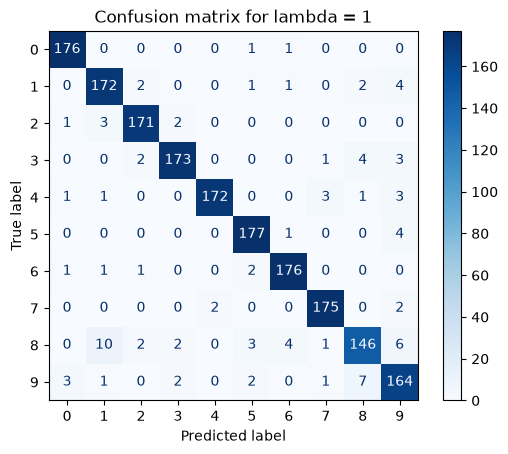

In [12]:
Astar = get_mmse(X, Y, 1)
Yhat = Astar @ X

Yhat_softmax = softmax(Yhat)
predicted_labels = np.argmax(Yhat_softmax, axis=0)
true_labels = nist.target

conf_matrix = metrics.confusion_matrix(true_labels, predicted_labels)   # Build the confusion matrix.

disp = metrics.ConfusionMatrixDisplay(
    confusion_matrix=conf_matrix,
    display_labels=np.arange(10)
)

disp.plot(cmap="Blues")
plt.title(f"Confusion matrix for lambda = {1}")
plt.show()

- The confusion matrix shows not only the total accuracy, but also which classes are confused with each other. Large values on the diagonal indicate correct predictions. Off-diagonal values show mistakes, for example when images of one digit are classified as another digit. This helps identify which digit classes are harder for the model to distinguish.

## Part 2 - Kernel regression

A kernel based predictor differs from a linear predictor in that it performs linear prediction on a transformed version of the input rather than of the input directly.
The transformation is performed by a function (let's call it $\boldsymbol\phi$) mapping input vectors to vectors in a space of arbitrary dimension $N>d$, i.e. $\boldsymbol\phi:\mathbb{R}^d\rightarrow\mathbb{R}^N$.
The prediction for a vector $\mathbf{x}\in\mathbb{R}^d$ is written as\begin{equation}
    \hat{\mathbf{y}}=\mathbf{w}^T\boldsymbol\phi(\mathbf{x}), 
\end{equation}
where $\mathbf{w}$ are parameters of the predictor.
In other words, kernel predictors are linear predictors in higher dimensional spaces.

For this part of the project, refer to the theory presented in tutorial 1 section 1.4.
The implementation tasks below are the ones proposed in the in question 4, 5 and 6.

### Task

- Implement a function in Python that calculates the Gram matrix associated with a linear kernel.
Your function should take as argument two sets of vectors in $\mathbb{R}^d$ in the form of two matrices, e.g. $X_1\in\mathbb{R}^{d\times n}$ and $X_2\in\mathbb{R}^{d\times m}$, and return the Gram matrix $K\in\mathbb{R}^{n\times m}$.


In [13]:
def my_linear_kernel(X1, X2):
    """ Applies a linear kernel to two inputs datasets
    Given
        X1: (d,n) ndarray
        X2: (d,m) ndarray
    Returns
        (n,m) ndarray
    """
    return X1.T @ X2

### Task

- Similarly, implement a function in Python that calculates the Gram matrix associated with a RBF kernel.

In [14]:
def my_rbf_kernel(X1, X2, gamma=1):
    """ Applies a RBF kernel of parameter gamma to two inputs datasets
        Given
            X: (d,n) ndarray
            Y: (d,m) ndarray
        Returns
            (n,m) ndarray
    """
    # k(x_i, x_j) = exp(-gamma * ||x_i - x_j||^2)
    return np.exp(-gamma * 
                  (np.sum(X1**2, axis=0).reshape(-1, 1) + 
                   np.sum(X2**2, axis=0).reshape(1, -1) - 2 * X1.T @ X2)) 
                # ||x_i - x_j||^2 = ||x_i||^2 + ||x_j||^2 - 2 x_i.T x_j

- using formula:
$$
||x_i - x_j||^2 = ||x_i||^2 + ||x_j||^2 - 2 x_i^T x_j
$$
$$
k(x_i, x_j) = exp(-gamma * ||x_i - x_j||^2)
$$

**kernel regression formula** $$ Yhat = Y (K + lambda I)^(-1) K_test $$
where $$ K = kernel(X_train, X_train) $$ and $$ K_test = kernel(X_train, X_test) $$
since we are testing on the same dataset now: X_train = X_test = X

In [15]:
def kernel_regr_pred(X_train, Y_train, X_test, kernel_func, lam=1, **kernel_params):
    # X_train has shape (d, n), so n is the number of columns.
    n = X_train.shape[1]

    K = kernel_func(X_train, X_train, **kernel_params)
    K_test = kernel_func(X_train, X_test, **kernel_params)

    # Yhat = Y_train (K + lambda I)^(-1) K_test
    Yhat = Y_train @ np.linalg.inv(K + lam * np.eye(n)) @ K_test
    return Yhat

##### Testing Linear Kernel

In [16]:
Yhat_kernel_linear = kernel_regr_pred(X, Y, X, my_linear_kernel, lam=1)

predicted_labels_linear = np.argmax(softmax(Yhat_kernel_linear), axis=0)
accuracy_kernel_linear = np.mean(predicted_labels_linear == nist.target)

print("Kernel regression with linear kernel accuracy: ", accuracy_kernel_linear)
print("MSE: ", mse(Y, Yhat_kernel_linear))

Kernel regression with linear kernel accuracy:  0.9471341124095715
MSE:  0.031003030804655014


##### Testing RBF Kernel

In [17]:
# Gamma controls how local the similarity measure is.
gamma_values = [0.0001, 0.001, 0.01, 0.1, 1, 10]

print("Kernel regression with RBF:")
for gamma in gamma_values:
    Yhat_kernel_rbf = kernel_regr_pred(X, Y, X, my_rbf_kernel, lam=1, gamma=gamma)

    predicted_labels_rbf = np.argmax(softmax(Yhat_kernel_rbf), axis=0)
    accuracy_kernel_rbf = np.mean(predicted_labels_rbf == nist.target)

    print("gamma:", gamma, "accuracy:", accuracy_kernel_rbf, "MSE:", mse(Y, Yhat_kernel_rbf))

Kernel regression with RBF:
gamma: 0.0001 accuracy: 0.9749582637729549 MSE: 0.019696379511389788
gamma: 0.001 accuracy: 0.9994435169727324 MSE: 0.003607769206791303
gamma: 0.01 accuracy: 1.0 MSE: 0.01807349473889545
gamma: 0.1 accuracy: 1.0 MSE: 0.024998069470958638
gamma: 1 accuracy: 1.0 MSE: 0.02499999999999998
gamma: 10 accuracy: 1.0 MSE: 0.025


In [18]:
print("Part 1 linear model accuracy:", accuracy)

Part 1 linear model accuracy: 0.9471341124095715


### **Conclusion**
The RBF kernel regression performs better than the linear model. For small gamma, the model is smoother and reaches about 97.5% accuracy. For gamma values from 0.01 and above, the model achives 100% training accuracy. That is showing that the RBF kernel is flexible enough to fit the training data perfectly, but that is because training and evaluation are done on the same dataset, this may indicate overfitting.


## Part 3 - Kernel substitution (SVM)

In this part of the project, you are going to implement the optimization problem of the Support Vector Machine (SVM) and compare its performances with the algorithms of the previous part.
For simplicity and to keep the focus on the optimization problem, we will implement SVM for a binary classification task.

### Dataset

The dataset we used for linear prediction is a multiclass classification dataset, we thus need to adapt the dataset to perform a binary classification task.

#### Task
- Come up with a binary classification task on the image dataset we introduced above. Present in details the input and target data you will be using.
- Compute the baseline performance on this new task with the linear prediction algorithm in part 1.

### Idea

- We can just choose images of digits 0 and 1, then convert labels into binary labels: digits 0 -> -1 and digit 1 -> 1
- Each image is represented as a 64-dimensional vector, we are going to use in the end y ∈ {-1, +1}


In [19]:
a = 0
b = 1

bin_mask = (nist.target == a) | (nist.target == b)      # [True, True, False, False, ..., True, False] checks if the label is equal to 0 or 1

X_bin = X[:, bin_mask]   # Keep only the image vectors belonging to digits 0 and 1
labels_bin = nist.target[bin_mask]
Y_bin = np.where(labels_bin == a, -1, 1).reshape(1, -1)   # digit 0 becomes -1, digit 1 becomes +1

print("X_binary shape:", X_bin.shape)
print("Y_binary shape:", Y_bin.shape)
print("Labels:", np.unique(Y_bin))

X_binary shape: (64, 360)
Y_binary shape: (1, 360)
Labels: [-1  1]


### Baseline performance with linear prediction from part 1
The model is trained using theh same regression formula:

$$
A^\star = YX^T(XX^T + \lambda I)^{-1}
$$

Since it's binary classification, the model outputs one score per sample:

$$
\hat{y} \geq 0 \Rightarrow +1, \quad \hat{y} < 0 \Rightarrow -1
$$

In [20]:
lam = 1
# Train the linear classifier from Part 1 on the binary dataset
A_bin = get_mmse(X_bin, Y_bin, lam)
Yhat_bin = A_bin @ X_bin        # Positive score means class +1, negative score means class -1

predicted_bin = np.where(Yhat_bin >= 0, 1, -1)
baseline_accuracy = np.mean(predicted_bin == Y_bin)

print("baseline lin acc: ", baseline_accuracy)

baseline lin acc:  1.0


### Observation
The baseline linear predictor achives high accuracy on the binary task, this is expected because digits 0 and 1 are visually different

### The SVM optimization problem

Recall that the optimization problem of a Support Vector Machine can be written as a quadratic program (QP):
\begin{equation}
    \underset{\mathbf{w}}{\text{minimize }} \frac{1}{2} ||\mathbf{w}||_2 \\
    \text{subject to } (\mathbf{w}^T\phi(\mathbf{x}_i) + \mathbf{b})\mathbf{y}_i \geq 0, \text{ for } i=1,\cdots,n.
\end{equation}

This initial problem is to be reformulated before it can be implemented.
This is because this problem depends upon function $\phi$, which as we saw, leads to a vector of infinite dimension for the RBF kernel and cannot be implemented.
The problem is to be reformulated into another QP where we can use the Gram matrix associated with the RBF kernel on the training data instead of $\phi$.

### Task
- Make sure that you understood the derivation of the problem in tutorials 4-5 !

### Implementation

In Python you can find a lot of libraries to help you solve QPs with efficient algorithms.
One such library is `cvxopt`. 
In this library you will find an algorithm for solving quadratic problems formulated in a standard way.

The solver is implemented in function `cvxopt.solvers.qp` and solves problems formulated as:

\begin{align}
\underset{\mathbf{w}}{\text{minimize }}\quad&    \frac{1}{2}\mathbf{w}^T P\mathbf{w} + \mathbf{q}^T\mathbf{w}\\
\text{subject to } \quad&   G\mathbf{w} <= \mathbf{h}\\
            & A\mathbf{w} = \mathbf{b}.
\end{align}

**Input arguments**

- P is a n x n dense or sparse 'd' matrix with the lower triangular part of P stored in the lower triangle.  Must be positive semidefinite.

- q is an n x 1 dense 'd' matrix.

- G is an m x n dense or sparse 'd' matrix.

- h is an m x 1 dense 'd' matrix.

- A is a p x n dense or sparse 'd' matrix.

- b is a p x 1 dense 'd' matrix or None.

- solver is None or 'mosek'.

The default values for G, h, A and b are empty matrices with zero rows.

You will find the complete doc here : http://cvxopt.org/index.html

### Task 
- Implement the support vector machine optimization algorithm using the `cvxopt` library. Your algorithm should work with the linear and RBF kernels.

In [21]:
from cvxopt import matrix, solvers

def train_svm(X_train, Y_train, kernel_function, lam=1, treshold=1e-5, **kernel_params):
    y = Y_train.flatten().astype(float)
    n = X_train.shape[1]

    K = kernel_function(X_train, X_train, **kernel_params)

    P = np.outer(y, y) * K
    q = -np.ones(n)
    G = -np.eye(n)
    h = np.zeros(n)
    A = y.reshape(1, -1)
    b = np.array([0.0])

    solvers.options["show_progress"] = False

    solution = solvers.qp(
        matrix(P),
        matrix(q),
        matrix(G),
        matrix(h),
        matrix(A),
        matrix(b)
    )

    # Support vectors are points with nonzero alpha
    # A threshold is used because very small alpha values are numerical noise
    alpha = np.array(solution["x"]).flatten()
    support_indices = np.where(alpha > treshold)[0]

    bias_val = []
    for i in support_indices:
        prediction_without_bias = 0

        for j in support_indices:
            prediction_without_bias += alpha[j] * y[j] * K[j, i]

        bias_val.append(y[i] - prediction_without_bias)
        
    # Average over support vectors for a more stable bias estimate
    bias = np.mean(bias_val)

    return alpha, bias, support_indices


def svm_prediction(X_train, X_test, y_train, alpha, bias, support_indices, kernel_func, **kernel_params):
    y = y_train.flatten().astype(float)
    K_test = kernel_func(X_train[:, support_indices], X_test, **kernel_params)

    scores = (alpha[support_indices] * y[support_indices]) @ K_test + bias
    predictions = np.where(scores >= 0, 1, -1)
    
    return predictions, scores

In [22]:
# linear 
alpha_linear, bias_linear, support_linear = train_svm(X_bin, Y_bin, my_linear_kernel)
prediction_linear_svm, scores_linear_svm = svm_prediction(X_bin, X_bin, Y_bin, alpha_linear, bias_linear, support_linear, my_linear_kernel)
acc_linear_svm = np.mean(prediction_linear_svm == Y_bin.flatten())

# rbf
alpha_rbf, bias_rbf, support_rbf = train_svm(X_bin, Y_bin, my_rbf_kernel, gamma=0.001)
prediction_rbf_svm, scores_rbf_svm = svm_prediction(X_bin, X_bin, Y_bin, alpha_rbf, bias_rbf, support_rbf, my_rbf_kernel, gamma=0.001)
acc_rbf_svm = np.mean(prediction_rbf_svm == Y_bin.flatten())

print("Linear SVM accuracy:", acc_linear_svm)
print("Number of support vectors:", len(support_linear))

print("RBF SVM accuracy:", acc_rbf_svm)
print("Number of support vectors:", len(support_rbf))


Linear SVM accuracy: 1.0
Number of support vectors: 19
RBF SVM accuracy: 1.0
Number of support vectors: 61


- Both the linear SVM and the RBF SVM achieve 100% accuracy on the binary classification task. This indicates that the selected classes are separable in the training data.


### SVM implementation

The SVM is solved using the dual formulation. In the dual problem the unknowns are the coefficients alpha_i one for each training sample. The data appears only through the kernel matrix:

$$
K_{ij} = k(x_i, x_j)
$$

For the quadratic programming solver the SVM problem is written in the form:

$$
\min_\alpha \frac{1}{2}\alpha^T P \alpha + q^T \alpha
$$

where

$$
P_{ij} = y_i y_j k(x_i, x_j)
$$

and q is a vector of -1's. The constraints enforce alpha_i >= 0 and

$$
\sum_i \alpha_i y_i = 0
$$

After solving for alpha the support vectors are the samples with nonzero alpha_i. These are the training points that define the SVM decision boundary.

### Model evaluation

Now that the SVM is implemented, we can test it and compare its performances with other methods.


### Tasks
- Compare the performances of the linear and RBF kernel based SVM on the binary classification task.
- Study the influence of the RBF's kernel scaling parameter.
- What is the difference between a linear SVM and the linear classification algorithm (with $\lambda=0$) of part 1 ?
- Compare the performances of the linear algorithms with the RBF kernel based SVM.
- Discuss your findings

In [23]:
class SupportVectorMachine(object):
    
    def __init__(self, C=1, kernel=None):
        self.C = C
        self.kernel = kernel    # linear or RBF
        # These attributes will be filled after training
        self.lagr_multipliers = None
        self.support_vectors = None
        self.support_vector_labels = None
        self.intercept = None

    def fit(self, X, y):
        y = y.flatten().astype(float)
        n = X.shape[1]

        K = self.kernel(X, X)

        P = np.outer(y, y) * K
        q = -np.ones(n)
        G = np.vstack((-np.eye(n), np.eye(n)))
        h = np.hstack((np.zeros(n), self.C * np.ones(n)))
        A = y.reshape(1, -1)
        b = np.array([0.0])

        solvers.options["show_progress"] = False

        # Solve the quadratic programming problem
        solution = solvers.qp(
            matrix(P, tc="d"),
            matrix(q, tc="d"),
            matrix(G, tc="d"),
            matrix(h, tc="d"),
            matrix(A, tc="d"),
            matrix(b, tc="d")
        )

        alpha = np.array(solution["x"]).flatten()   # Extract alpha values from the solution
        threshold = 1e-5
        support_indices = np.where(alpha > threshold)[0]    # Support vectors are samples with alpha larger than the threshold
        self.lagr_multipliers = alpha[support_indices]
        self.support_vectors = X[:, support_indices]
        self.support_vector_labels = y[support_indices]

        # Use margin support vectors to estimate the bias term b.
        # These are support vectors with 0 < alpha_i < C.
        margin_indices = np.where((alpha > threshold) & (alpha < self.C - threshold))[0]
        if len(margin_indices) == 0:
            margin_indices = support_indices

        # Compute b from y_i - sum_j alpha_j y_j K(x_j, x_i).
        bias_values = []
        for i in margin_indices:
            decision_value = np.sum(alpha[support_indices] * y[support_indices] * K[support_indices, i])
            bias_values.append(y[i] - decision_value)

        self.intercept = np.mean(bias_values)

        return self

    def predict(self, X):
        # Compute kernel values between support vectors and test samples
        K = self.kernel(self.support_vectors, X)

        # Compute the SVM decision score for each test sample
        scores = (self.lagr_multipliers * self.support_vector_labels) @ K + self.intercept

        return np.where(scores >= 0, 1, -1)

linear_svm = SupportVectorMachine(C=1, kernel=my_linear_kernel)
linear_svm.fit(X_bin, Y_bin)

pred_linear_svm = linear_svm.predict(X_bin)
acc_linear_svm = np.mean(pred_linear_svm == Y_bin.flatten())

# We first train an SVM using the linear kernel. This is still a linear decision boundary, but unlike the Part 1 classifier, it is trained by maximizing the margin
print("Linear SVM accuracy:", acc_linear_svm)
print("Linear SVM support vectors:", len(linear_svm.lagr_multipliers))

# rbf gamma
gamma_values = [0.0001, 0.001, 0.01, 0.1, 1, 10]

for gamma in gamma_values:
    rbf_kernel = lambda X1, X2: my_rbf_kernel(X1, X2, gamma=gamma)

    # Train an SVM using this RBF kernel
    rbf_svm = SupportVectorMachine(C=1, kernel=rbf_kernel)
    rbf_svm.fit(X_bin, Y_bin)

    pred_rbf_svm = rbf_svm.predict(X_bin)
    acc_rbf_svm = np.mean(pred_rbf_svm == Y_bin.flatten())

    print("gamma:", gamma, "accuracy:", acc_rbf_svm, "support vectors:", len(rbf_svm.lagr_multipliers))

# part1 linear classifier with lam=0
A_linear_no_reg = get_mmse(X_bin, Y_bin, lam=0)
Yhat_linear_no_reg = A_linear_no_reg @ X_bin

pred_linear_no_reg = np.where(Yhat_linear_no_reg >= 0, 1, -1)
acc_linear_no_reg = np.mean(pred_linear_no_reg == Y_bin)

print("Linear classifier lambda=0 accuracy:", acc_linear_no_reg)

Linear SVM accuracy: 1.0
Linear SVM support vectors: 19
gamma: 0.0001 accuracy: 1.0 support vectors: 43
gamma: 0.001 accuracy: 1.0 support vectors: 61
gamma: 0.01 accuracy: 1.0 support vectors: 347
gamma: 0.1 accuracy: 1.0 support vectors: 360
gamma: 1 accuracy: 1.0 support vectors: 360
gamma: 10 accuracy: 1.0 support vectors: 360
Linear classifier lambda=0 accuracy: 1.0


### Discussion
All methods have 100% training accuracy on the binary task, which indicates that the selected digits are easy to separate. The linear classifier and linear SVM both use linear decision boundaries, but the linear classifier minimizes squared error while the SVM maximizes the margin.

The rbf SVM also reaches 100% accuracy for all tested gamma values. But the number of support vectors increases as gamma becomes larger. This happens because larger gamma makes the rbf kernel more local so more training samples influence the decision boundary. For large gamma almost all samples become support vectors, which may indicate overfitting.

## Part 4a - Neural networks (Back-prop)

In this part we train a 1 hidden layer neural network on the artificial two moons dataset.
The particularity is that we manually implement the update rule of a backpropagation algorithm.
The goal is to give an insight on how machine learning toolboxes work under the hood, and to understand why we need these toolboxes to build complex training pipelines.
Here we do not use such toolboxes, but rather implement a back propagation algorithm using the numpy library.

The code was found here:
- Walkthrough backpropagation algorithm: https://cs231n.github.io/optimization-2/

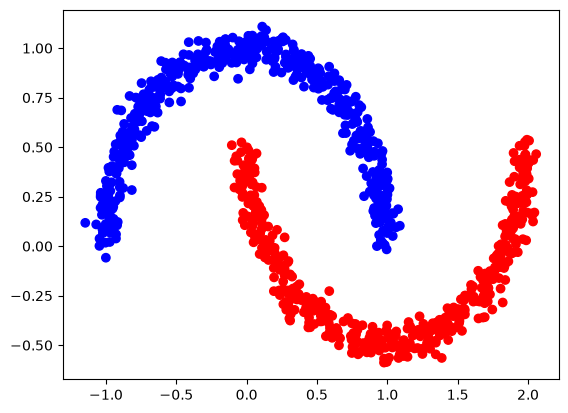

In [24]:
x,y = make_moons(n_samples=1000, noise=0.05)    # # x contains 2D coordinates, y contains class labels 0 or 1
y = np.hstack([1-y[:,None],y[:,None]])      # one hot format 0->[1,0] and 1->[0,1]

colors = 'rb'
c_ = [colors[yy] for yy in y[:,0]]

fig,ax=plt.subplots()
ax.scatter(x[:,0], x[:,1], c=c_);

In [25]:
# Network definitions

d = 2 # Input space dimension
n1 = 2 # First layer hidden size
q = 2  # Target space dimension

# Activation function
def relu(x):
    # if x>0 keep x else return 0
    return np.maximum(0,x)

# learning rate
lr=0.5

# Initialize NN
hidden_sizes = [(d,n1), (n1,q)]
print(hidden_sizes)

[(2, 2), (2, 2)]


### Task

- Using the skeleton of code below, write the batch gradient descent algorithm for a 1-hidden layer network.

Text(0, 0.5, 'Loss')

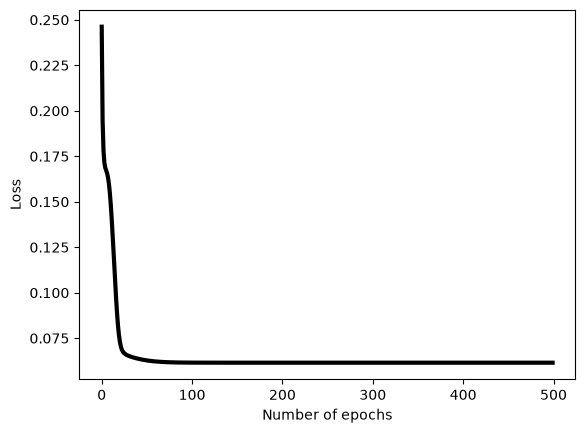

In [26]:
# Weight initialization

w1 = np.random.randn(hidden_sizes[0][1],hidden_sizes[0][0])
w2 = np.random.randn(hidden_sizes[1][1],hidden_sizes[1][0])

# Training loop
nepochs = 500

# We will save the loss at every epoch
loss = np.zeros(nepochs)

for ix in range(nepochs):
    n_samples = x.shape[0]
    # Forward pass: compute y_pred    
    #
    ## Task 1: Write the forward pass
    # Solution
    h = x @ w1.T
    h_relu = relu(h)
    y_pred = h_relu @ w2.T
    
    # Compute loss
    loss[ix] = (0.5) * np.square(y_pred - y).mean()

    # Gradient of loss wrt network's output
    d3 = y_pred - y
    
    ## Task 2: Implement
    grad2 = d3.T @ h_relu / n_samples
    dh_relu = d3 @ w2
    dh = dh_relu.copy()
    dh[h <= 0] = 0
    grad1 = dh.T @ x / n_samples
    
    # Update weights
    #
    ## Task 3
    w1 = w1 - lr * grad1
    w2 = w2 - lr * grad2

# Plot the loss
fig,ax=plt.subplots()
ax.plot(loss,'k',lw=3)
ax.set_xlabel("Number of epochs")
ax.set_ylabel("Loss")

### Manual backpropagation

In this part, I train a small neural network manually using NumPy. The network has one hidden layer with a ReLU activation. The forward pass computes predictions from the input data, and the backward pass computes gradients of the loss with respect to the weights.

Each training epoch consists of four steps:

1. Forward pass: compute the hidden layer activations and the output prediction.
2. Loss computation: measure the difference between the predicted output and the true one-hot target.
3. Backward pass: compute the gradients of the loss with respect to the two weight matrices.
4. Weight update: update the weights in the opposite direction of the gradient.

The weights are updated using batch gradient descent:

$$
W \leftarrow W - \eta \nabla W
$$

where eta is the learning rate. Since this is batch gradient descent, each update uses all training samples.

### Task

- Evaluate the performances of the algorithm on the classification dataset.
- Compare the performances of the neural network with the algorithms implemented in the previous parts (except the GP)

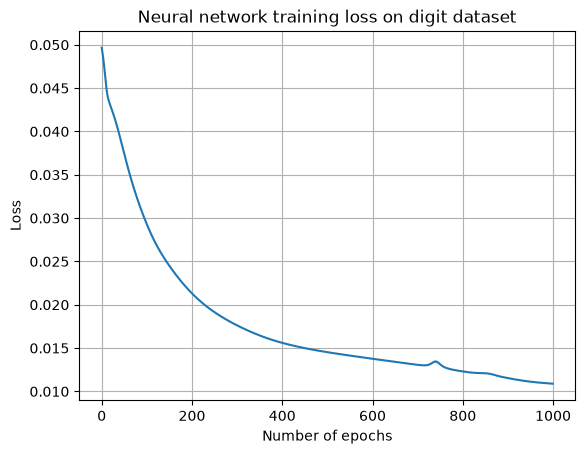

Neural network accuracy: 0.9682804674457429
Part 1 linear model accuracy: 0.9471341124095715
Kernel linear accuracy: 0.9471341124095715
Kernel RBF accuracy: 1.0


In [27]:
x_nn = X.T
y_nn = Y.T

d = x_nn.shape[1]   # 64 pixels per digit image for input dimensions
q = y_nn.shape[1]   # 10 digit classes for output dimensions

n1 = 16     # Hidden layer size
lr = 0.01   # learning rate
nepochs = 1000

w1 = 0.01 * np.random.randn(n1, d)
w2 = 0.01 * np.random.randn(q, n1)

loss_nn = np.zeros(nepochs)

for ix in range(nepochs):
    n_samples = x_nn.shape[0]

    # Forward pass
    h = x_nn @ w1.T
    h_relu = relu(h)
    y_pred = h_relu @ w2.T

    # Loss
    loss_nn[ix] = 0.5 * np.square(y_pred - y_nn).mean()

    # Backward pass
    d3 = y_pred - y_nn

    grad2 = d3.T @ h_relu / n_samples

    dh_relu = d3 @ w2
    dh = dh_relu.copy()
    dh[h <= 0] = 0

    grad1 = dh.T @ x_nn / n_samples

    # Update weights
    w1 = w1 - lr * grad1
    w2 = w2 - lr * grad2

# plot loss
plt.figure()
plt.plot(loss_nn)
plt.xlabel("Number of epochs")
plt.ylabel("Loss")
plt.title("Neural network training loss on digit dataset")
plt.grid(True)
plt.show()

#calculate accuracy
h = x_nn @ w1.T
h_relu = relu(h)
y_pred = h_relu @ w2.T
predicted_labels_nn = np.argmax(y_pred, axis=1)
true_labels_nn = np.argmax(y_nn, axis=1)
accuracy_nn = np.mean(predicted_labels_nn == true_labels_nn)

print("Neural network accuracy:", accuracy_nn)
print("Part 1 linear model accuracy:", accuracy)
print("Kernel linear accuracy:", accuracy_kernel_linear)
print("Kernel RBF accuracy:", accuracy_kernel_rbf)

- The neural network achieved an accuracy of approximately 96.55%, which is higher than the linear model and linear kernel regression accuracy of approximately 94.71%. This improvement is expected because the neural network contains a nonlinear hidden layer with ReLU activation, allowing it to learn more complex relationships than a purely linear model.
- I also tested different hidden layer sizes and numbers of epochs. In my experiments, a hidden size of 16 gave the best result among 8, 16, 32, and 64, while increasing the number of epochs up to 1000 improved the performance.

## Part 4b - Neural networks (CNN architecture)
### Supervised learning in Pytorch
Supervised learning is a type of machine learning problem a target quantity has to be infered from a set of input samples.
Classical inference tasks are regression, where a continuous target quantities has to be infered, and classification, where a discrete target is to be infered.
In this notebook we consider an image classification task.
Classically, image classification tasks are performed with careful filter engineering and feature extraction methods.
The features were then classified using classical classification algorithms, such as logistic regression or Support Vector Machine.
The classification algorithm was then tested against metrics such as mean squared error, accuracy, f1-score, ...

In 1990, the model `Lenet` was proposed.
`LeNet` directly maps input images to their label without manual filter design and is learnable end-to-end.
This enables the feature extraction pipeline and the classification algorithm to be trained jointly, without requiring engineering choices.

This model uses convolutional neural networks (CNN), a type of hidden layer which can be used to extract features on images regardless of their spatial location.
The features are extracted gradually with several repetitions of convolutional layers, non-linear activations and  pooling layers.
After the features have been extracted, the model uses fully connected layers to perform the final mapping to the image label.

The architectire is depicted below:
![Architecture](lenet.png)

Convolutional layers, pooling layers, activation functions and fully connected layers are all functions that are differentiable with respect to (wrt) their parameters.
The model is constructed so that the output can be compared to the expected output using loss functions which are differentiable wrt their input.
This allows `LeNet` to be trained using backpropagation, a gradient descent algorithm which uses the chain rule to calculate the derivative of a loss function wrt the trainable parameter.



## Objective
In this notebook, the objective is to obtain a testing performance of the `LeNet` model on the KMNIST dataset.
To achieve this, we will define our model and train it from scratch.

We will introduce the steps which must be implemented when working with a supervised learning pipeline:
- Data preparation
- Model architecture
- Training algorithm
- Testing algorithm


## Dataset

We use the KMNIST dataset which is a supervised learning classification task.
The dataset consists of 60,000 images of size 28x28 and 10 classes.


## Requirements

Basic knowledge in pytorch, follow this introduction if necessary: https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html

- Make sure that torch and torchvision are installed in version:
`torch==1.10.1` and `torchvision==0.11.2`


In [28]:
import numpy as np
import torch
import torchvision
import matplotlib as mpl
import matplotlib.pyplot as plt
from torch.utils.data.sampler import SubsetRandomSampler
import torchvision.transforms as transforms

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.nn import Module
from torch import nn
import torch.nn.functional as F
opts= {
    "batch_size":64,
    "loss_fun": nn.CrossEntropyLoss,
    "optimizer_fun":optim.SGD,
    "optimizer_opts":{"lr":0.01, "momentum":0.9}
}
print("torch=={}".format(torch.__version__))
print("torchvision=={}".format(torchvision.__version__))
print("numpy=={}".format(np.__version__))
print("matplotlib=={}".format(mpl.__version__))

torch==2.14.1
torchvision==0.29.1
numpy==2.4.6
matplotlib==3.11.2


In this part the goal is to define, train and test a convolutional neural network on a classification dataset.
We introduce the key steps required to train and test any deep neural network architecture:

- Data preparation
- Model architecture
- Training algorithm
- Testing algorithm


For demonstration purpose, we use a supervised learning task on the KMNIST dataset.
The dataset can be downloaded as shown below:

In [29]:
%pip install --upgrade certifi

  Attempting uninstall: certifi
    Found existing installation: certifi 2026.7.22
    Uninstalling certifi-2026.7.22:
      Successfully uninstalled certifi-2026.7.22

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Training tensor shape: 60000 28 28
Number of classes: 10
Example images:


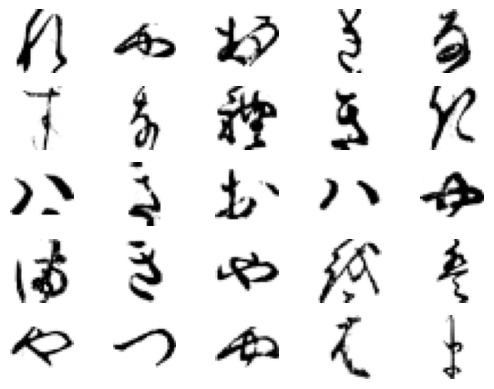

In [30]:
# Download and parse the dataset
# When working with images, the torchvision package provides useful tools to manipulate and convert image formats.
transform = transforms.Compose(
    [transforms.ToTensor()])

# Torchvision also distributes reference datasets represented in torch compatible objects
# We will save the downloaded dataset (~73MB) in a parent folder, in case we need it in another lab
trainset = torchvision.datasets.KMNIST(root='../data', train=True, download=False, transform=transform)
testset = torchvision.datasets.KMNIST(root='../data', train=False, download=False, transform=transform)

# We can look at our data dimension and plot some example images
n_samples,h,w = trainset.data.shape
print("Training tensor shape:", n_samples, h, w)
print("Number of classes:",len(trainset.classes))
print("Example images:")

plt.figure()
for i in range(25):
    ax=plt.subplot(5,5,i+1)
    img = trainset.data[i]
    ax.imshow(img, cmap="Greys")
    ax.axis('off')
plt.savefig("KMNIST.png")
plt.show()

## Step 1: Data preparation

Once the dataset is downloaded, the first step is typically to cast the data into classes specifically design for model training.

Such classes are helpful to abstract batch-level operations such as shuffling, parsing, batch spliting, batch 
normalization.

In `torch`, such a class is called `DataLoader` and is implemented in [`torch.utils.data.DataLoader`](https://pytorch.org/docs/stable/data.html?highlight=dataloader#torch.utils.data.DataLoader)

- **Task 1**: Create `DataLoader` instances built on the training and testing datasets. The dataloader should be initialized such that it shuffles the input samples, and use a batch size of `64` samples.

In [31]:
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=opts["batch_size"],
    shuffle=True
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=opts["batch_size"],
    shuffle=True
)

inputs, labels = next(iter(trainloader))

print("Input batch shape:", inputs.shape)
print("Label batch shape:", labels.shape)

Input batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


## Step 2: Model definition

Once the dataset is downloaded and cast in the right data structure, we must define the model which will process the data batches.

In pytorch, models are implemented by inheriting the `nn.Module` class.
When implementing a new model in pytorch, one must define the different layers and activation functions and forward pass computation. The nice thing about using a deep learning toolbox is that the forward pass and the gradient computation of the most famous layer types are readily available.

For this step we will implement the LeNet neural network architecture.

- **Task 2**: Implement the LeNet architecture using the class skeleton provided below. The details of the model, can be found here: http://yann.lecun.com/exdb/publis/pdf/lecun-01a.pdf. The main part of the class is defined for you and you are left with the implementation of the last dense layer which takes as input 84-dimensional features and outputs 10-dimensional target vectors.


Hint:
- All the required layer class are implemented in pytorch in the `nn` module.
- Functional for relu can be found in the `nn.functional` module.
- The useful classes are: 
    - nn.Linear
    - F.relu

In [32]:
""" Network definition
    The role of the Net class is to compute the forward pass of a batch of images.
    
    The __init__ function is called when the class is instanciated.
        It must contain the declaration of the different trainable and non trainable layers.
        The layers must be defined as attributes (fields) of the Net class.
        This function can take the network's hyper-parameters as arguments.
        Here we use a famous network so we can hard code the layer's sizes.
        The activation and pooling functions can be defined here or in the forward function.
    
    The forward function is called when we want a batch of images to pass through the network layers.
        It is where we describe the architecture of the network by chaining the layers together.
        It must take a batch as input, and output the network's prediction.
"""


# Task 2
class Net(Module):
    def __init__(self):
        super(Net, self).__init__()
        # First convolution layer:
        # input channels = 1 because KMNIST images are grayscale
        # output channels = 6 feature maps
        # kernel size = 5x5
        # padding=2 keeps the spatial size 28x28 after convolution
        self.conv1 = nn.Conv2d(1, 6, 5, padding=2)
        # Second convolution layer:
        # input channels = 6 from previous layer
        # output channels = 16 feature maps
        # kernel size = 5x5
        self.conv2 = nn.Conv2d(6, 16, 5)

        # After convolution and pooling, the feature maps have size 16 x 5 x 5
        # Flattening gives 16*5*5 = 400 features
        self.fc1 = nn.Linear(400, 120)
        # Fully connected layer from 120 features to 84 features
        self.fc2 = nn.Linear(120, 84)
        # Final layer outputs 10 scores, one for each class
        self.fc3 = nn.Linear(84, 10)
    
    def forward(self, x):
        y = F.relu(self.conv1(x))   # Apply first convolution followed by ReLU
        # As mentioned in the paper, the subsampling operation keeps the maximum value in 2 x 2 patches of image.

        y = F.max_pool2d(y, (2, 2))     # This reduces spatial size from 28x28 to 14x14
        y = F.relu(self.conv2(y))
        y = F.max_pool2d(y, (2, 2))     # Spatial size becomes 5x5
        
        # Aggregate (flatten) all the remaining extracted feature maps
        y = y.view(y.shape[0], -1)
        y = F.relu(self.fc1(y))
        y = F.relu(self.fc2(y))
        y = self.fc3(y)

        return y

# Instantiation, (call the __init__ function of the class)
net = Net()


In [33]:
from operator import mul
from functools import reduce

l=nn.Conv2d(1, 6, 5, padding=2, bias=True)
params=[ll for ll in l.parameters()]
print("Number of parameter tensors:",len(params))
print("Kernel tensor shape:", params[0].shape)
print("Kernel number of parameters:",reduce(mul,params[0].shape))
try:
    print("Bias tensor shape:", params[1].shape)
except:
    pass

Number of parameter tensors: 2
Kernel tensor shape: torch.Size([6, 1, 5, 5])
Kernel number of parameters: 150
Bias tensor shape: torch.Size([6])


### Model definition

The input images have shape 1x28x28. The first convolution maps the grayscale image to 6 feature maps, followed by ReLu and max pooling. The second convolution maps 6 feature maps to 16 feature maps, followed by ReLu and max pooling.

After that, the feature maps have shape 16x5x5 so they are flattened into 400 features. These features are passed through fully connected layers of sizes 120, 84 and 10 output scores.

## Step 3: Training loop

Now the data object are created and the network architecture is implemented.
Before our network can be trained, we must define the optimization criterion, the type of optimizer we will use and finally, write the training algorithm.

The optimization criterion we use is the `CrossEntropyLoss` from the `torch.nn` module.
The optimizer we use is the stochastic gradient descent `SGD`from the `torch.optim` module.

- **Task 3**: Your task is now to write the training loop for our neural network architecture.

Hint:
The training procedure may be decomposed into the following steps:

- Forward pass
- Loss evaluation
- Gradient computation
- Parameters update

In [34]:
# Instantiation of the loss function defined in the `opts` dictionary
criterion = opts["loss_fun"]()

# Instantiation of the optimizer with all the network's trainable parameters as arguments
optimizer = opts["optimizer_fun"](net.parameters(), **opts["optimizer_opts"])



# Task 3
for epoch in range(2):  # loop over the dataset multiple times
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # We want the gradients of each batches to be calculated independently. 
        # We discard previously computed gradients by setting them to 0
        optimizer.zero_grad()

        ####
        # forward + evaluation + backward + optimize
        ####
        
        # During the forward pass, pytorch automatically accumulates the gradient of the output of each layer 
        # with respect to its input.
        outputs = net(inputs)
        
        # The loss can be evaluated by simply calling the criterion function with both the predicted and true labels
        loss = criterion(outputs, labels)
        
        # The final quantity required to run the update rule on the trainable parameters is the gradient of the loss
        # with respect to the parameters. The appropriate gradients must have been accumulated during the forward pass
        # and what this next step does is apply the chain rule.
        loss.backward()
        
        # Once the gradients are calculated, we can perform a step of the update rule using the optimizer object:
        optimizer.step()
        
        
        # Print statistics
        running_loss += loss.item() # Accumulate losses into running_loss
        if i % 200 == 199:    # print every 200 mini-batches
            print('[%d, %5d] loss: %.3f' %
                  (epoch + 1, i + 1, running_loss))
            running_loss = 0.0

print('Finished Training')


[1,   200] loss: 349.150
[1,   400] loss: 117.273
[1,   600] loss: 69.339
[1,   800] loss: 53.445
[2,   200] loss: 36.526
[2,   400] loss: 32.154
[2,   600] loss: 30.850
[2,   800] loss: 30.176
Finished Training


### Training loop

For each batch, the model performs a forward pass, computes the cross-entropy loss, backpropagates the gradients, and updates the trainable parameters using stochastic gradient descent.

Before each backward pass, the gradients are reset using `optimizer.zero_grad()` so that gradients from different mini-batches do not accumulate.

# Gradient computation in PyTorch
Let us investigate the backward gradient pass a bit more.
You will find a detailed explaination of backpropagation in pytorch [here](https://amsword.medium.com/understanding-pytorchs-autograd-with-grad-fn-and-next-functions-b2c4836daa00)

<img src="./LeTweet.png" width="500">


## A simple example first

Let us go look at a simple example taken from [here](https://amsword.medium.com/understanding-pytorchs-autograd-with-grad-fn-and-next-functions-b2c4836daa00)

We define a simple differentiable operation:
- the element wise multiplication of two tensors (`z=x*y`)
- followed by the sum of the resulting elements (`l=z.sum()`).

The result tensor `l` has a `.grad_fn` attribute.
The `l.grad_fn` object has a next_functions attribute.
This will help us iterate backward on the computation graph, until we encounter the trainable weights (the leafs of the graph).

We would like to calculate the gradient of this operation wrt the two initial tensors.
- We first compute the gradients with a call to `.backward()`
- then we compute the gradients by iterating through the compute graph using the `grad_fn` attribute of the final tensor.

In [35]:
torch.manual_seed(6)
x = torch.randn(2, 1, requires_grad=True)
y = torch.randn(2, 1, requires_grad=True)
z = x * y
l = z.sum()
l.backward()
print("Gradient computed after the .backward() call:")
print(x.grad)
print(y.grad)
print()


torch.manual_seed(6)
x = torch.randn(2, 1, requires_grad=True)
y = torch.randn(2, 1, requires_grad=True)
z = x * y
l = z.sum()

dl = torch.tensor(1.)

back_sum = l.grad_fn
dz = back_sum(dl)
back_mul = back_sum.next_functions[0][0]
dx, dy = back_mul(dz)
back_x = back_mul.next_functions[0][0]
back_x(dx)

back_y = back_mul.next_functions[1][0]
back_y(dy)

print("Gradient computed after manual backprop on the compute graph:")
print(x.grad)
print(y.grad)

Gradient computed after the .backward() call:
tensor([[ 0.7185],
        [-0.6985]])
tensor([[-1.8744],
        [-0.9937]])

Gradient computed after manual backprop on the compute graph:
tensor([[ 0.7185],
        [-0.6985]], grad_fn=<CopyBackwards>)
tensor([[-1.8744],
        [-0.9937]], grad_fn=<CopyBackwards>)


We see that both approaches lead to the same gradients.

## A more systematic investigation

In [36]:
# We take the last inputs batch we encountered and run it through the network once again
outputs = net(inputs)

# We evaluate the loss 
loss = criterion(outputs, labels)

# The loss object contains a grad_fn attribute.
grad_fn = loss.grad_fn

# We write an recursive function to print the gradient computation functions we encounter.
# The functions named "AccumulateGrad" inform us that we have reached a Leaf node.
# When the leaf nodes are reached, the .grad attribute of the current tensor is ready to be populated with their gradient.
def print_back_fun(fun,i):
    if fun is None: 
        # Not sure why/when these None attributes occur
        pass
    
    elif fun.next_functions == (): 
        # When the list of next_functions is empty we reached a Leaf node, i.e. a parameter tensor
        print(i,";","Leaf",fun)
        
    else:
        # Print the current grad function and the depth of the recursion
        print(i,";", fun)
        # Iterate through the rest of the graph recursively, increase the depth of the recursion by 1
        list(map(lambda x: print_back_fun(x[0],i+1), fun.next_functions))


print_back_fun(grad_fn,0)

0 ; <NllLossBackward0 object at 0x1153b88b0>
1 ; <LogSoftmaxBackward0 object at 0x11dfca5c0>
2 ; <AddmmBackward0 object at 0x11e21b9d0>
3 ; Leaf <AccumulateGrad object at 0x11e21b190>
3 ; <ReluBackward0 object at 0x11e21b160>
4 ; <AddmmBackward0 object at 0x11e2181f0>
5 ; Leaf <AccumulateGrad object at 0x11e21bd60>
5 ; <ReluBackward0 object at 0x11e2196f0>
6 ; <AddmmBackward0 object at 0x11e21b670>
7 ; Leaf <AccumulateGrad object at 0x11db17e50>
7 ; <ViewBackward0 object at 0x11db17a90>
8 ; <MaxPool2DWithIndicesBackward0 object at 0x11db16b60>
9 ; <ReluBackward0 object at 0x11db170a0>
10 ; <ConvolutionBackward0 object at 0x11db169e0>
11 ; <MaxPool2DWithIndicesBackward0 object at 0x11db17220>
12 ; <ReluBackward0 object at 0x11db17d00>
13 ; <ConvolutionBackward0 object at 0x11db17820>
14 ; Leaf <AccumulateGrad object at 0x11db17a30>
14 ; Leaf <AccumulateGrad object at 0x11db16c20>
11 ; Leaf <AccumulateGrad object at 0x11db16cb0>
11 ; Leaf <AccumulateGrad object at 0x11db16f20>
7 ; <TBack

We encounter 10 leaf nodes, which corresponds to the number of parameter tensors in our network:

In [37]:
the_params=[p.shape for p in net.parameters()]
print("Number of parameter tensors",len(the_params),":")
the_params

Number of parameter tensors 10 :


[torch.Size([6, 1, 5, 5]),
 torch.Size([6]),
 torch.Size([16, 6, 5, 5]),
 torch.Size([16]),
 torch.Size([120, 400]),
 torch.Size([120]),
 torch.Size([84, 120]),
 torch.Size([84]),
 torch.Size([10, 84]),
 torch.Size([10])]

This means that, even before calling the `.backward()` function, the intermediate gradients are computed and stored during the forward pass.
The call to `.backward()` triggers the computation of the chain rule for each Leaf node (parameter tensor) of the computation graph we displayed above.


### Summary

This section investigates how PyTorch computes gradients automatically. When tensors are created with `requires_grad=True`, PyTorch records the operations applied to them in a computation graph.

Calling `.backward()` on the final loss value applies the chain rule through this graph and stores the gradients in the `.grad` attributes of the leaf tensors.

For the CNN, the loss object has a `grad_fn` attribute, which points to the backward computation graph. Traversing this graph shows the sequence of operations used to compute gradients for the network parameters.

The network has 10 trainable parameter tensors because it contains 5 trainable layers, and each layer has one weight tensor and one bias tensor.

# Step 4: Testing algorithm

Now that our network has been trained, we can measure the performance on the held out test dataset.
The measure which we will use is the accuracy.

- **Task 4**: Write the code necessary to compute the accuracy on the held out test set.

Hint:
 - To avoid unnecessary computations, make sure that the gradient is not computed while the test samples pass through the network.
 - A probabilistic interpretation of the network's output is not required when computing the accuracy. All we need is the index of the largest output. To get the probabilistic interpretation you can use a softmax.

In [38]:
# Accuracy score
# Task 4
from datetime import datetime

total=0
correct=0
start_time = datetime.now()
print("with torch.no_grad()")

# To avoid the computation of the gradients during the forward pass,
# We use the torch.no_grad() environment
net.eval()
# This saves memory and usually makes evaluation faster
with torch.no_grad():
    for data in testloader:

        images, labels = data
        outputs = net(images)   # Compute class scores

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

elapsed=(datetime.now()-start_time).total_seconds()

print('Accuracy of the network on the 10000 test images: %d %%' % (100 * correct / total))
print("runtime: {:.3f} sec".format(elapsed))

with torch.no_grad()
Accuracy of the network on the 10000 test images: 89 %
runtime: 0.411 sec


### with or without torch.no_grad() ?

In [39]:
print("without torch.no_grad()")

total=0
correct=0
start_time = datetime.now()
net.eval()

# To avoid the computation of the gradients during the forward pass,
# We use the torch.no_grad() environment
# with torch.no_grad():
for data in testloader:
    images, labels = data
    outputs = net(images)
    
    _, predicted = torch.max(outputs.data, 1)
    
    total += labels.size(0)
    correct += (predicted == labels).sum().item()

elapsed=(datetime.now()-start_time).total_seconds()

print('Accuracy of the network on the 10000 test images: %d %%' % (100 * correct / total))
print("runtime: {:.3f} sec".format(elapsed))

without torch.no_grad()
Accuracy of the network on the 10000 test images: 89 %
runtime: 0.388 sec


We see that when torch.no_grad() is used, the output tensors are not populated with the gradient functions `grad_fn`. This means that the gradients are not computed during the forward pass. The memory consumption of the forward pass is thus reduced. For large models you can expect a gain in runtime and memory footprint.

### Testing algorithm

To evaluate the CNN, I run the trained model on the held-out KMNIST test set. Since no learning happens during testing, I use `torch.no_grad()` to disable gradient tracking. This reduces memory usage and can make evaluation faster.

For each batch, the model outputs 10 scores, one for each class. The predicted class is the index of the largest score. Accuracy is computed as the number of correct predictions divided by the total number of test images.

Both versions give the same test accuracy because `torch.no_grad()` does not affect the forward computation or the model output. It only disables gradient tracking.